# Ion Gyrophase Bunching by EMIC Waves

author: Louis Richard\
Reproduces the gyrophase spectra of Fig. 1 of Li et al. (2022): electromagnetic ion cyclotron (EMIC) waves observed by MMS in the dawnside magnetosheath on 2020-01-14 bunch the ions in gyrophase. The gyrophase distributions are computed from the FPI ion skymaps with `mms.get_gyrophase_dist` and averaged over the four spacecraft, as in the paper.

Li, J.-H., Liu, Z.-Y., Zhou, X.-Z., et al. (2022). Anomalous resonance between low-energy particles and electromagnetic plasma waves. *Communications Physics*, 5, 300. https://doi.org/10.1038/s42005-022-01083-y

In [1]:
%matplotlib inline
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from pyrfu import mms, pyrf
from pyrfu.plot import use_pyrfu_style, plot_line, plot_spectr, make_labels

use_pyrfu_style(usetex=False)

## Define the time interval
The background field is low-pass filtered at 0.05 Hz, so the magnetic field is loaded over a longer interval.

In [2]:
tint = ["2020-01-14T19:23:30.000", "2020-01-14T19:23:50.000"]
tint_long = ["2020-01-14T19:21:30.000", "2020-01-14T19:25:50.000"]
mms_ids = [1, 2, 3, 4]

## Load data
Magnetic field (FGM) in GSE, and in DMPA, the coordinate system of the FPI skymaps, and the ion skymaps (FPI-DIS), from the public MMS archive on AWS.

In [3]:
b_gse, b_dmpa = [
    [
        mms.get_data(f"b_{cs}_fgm_brst_l2", tint_long, ic, False, source="aws")
        for ic in mms_ids
    ]
    for cs in ["gse", "dmpa"]
]
vdf_i = [
    mms.get_data("pdi_fpi_brst_l2", tint, ic, False, source="aws") for ic in mms_ids
]

## Background field and wave field
The background field $\mathbf{B}_0$ is low-pass filtered at 0.05 Hz and the wave field $\mathbf{B}_1$ band-pass filtered between 0.25 and 0.65 Hz, both averaged over the four spacecraft. The field-aligned coordinates are those of the paper and of `pyrf.convert_fac`: $\parallel$ along $\mathbf{B}_0$, $\perp_2 = \mathbf{B}_0 \times \hat{\mathbf{x}}$ (sunward), and $\perp_1$ completes the triad. They are computed in DMPA, whose $x$ axis is the sunward direction projected onto the spin plane (the paper uses GSE $x$, a few degrees away).

In [4]:
b0_dmpa = [pyrf.filt(b, 0.0, 0.05, 3) for b in b_dmpa]
b1_dmpa = pyrf.avg_4sc([pyrf.filt(b, 0.25, 0.65, 3) for b in b_dmpa])

# Wave field in field-aligned coordinates (perp1, perp2, par)
b1_fac = pyrf.convert_fac(b1_dmpa, pyrf.avg_4sc(b0_dmpa), [1, 0, 0])
b1_fac = pyrf.time_clip(b1_fac, tint)

# Phase angle of the wave field in the perpendicular plane
phi_b1 = np.rad2deg(np.arctan2(b1_fac.data[:, 1], b1_fac.data[:, 0]))
phi_b1 = pyrf.ts_scalar(b1_fac.time.data, phi_b1 % 360.0)

# Direction of the background field in GSE (the paper gives [-0.45, 0.05, 0.89])
b0_gse = pyrf.avg_4sc([pyrf.filt(b, 0.0, 0.05, 3) for b in b_gse])
pyrf.normalize(pyrf.time_clip(b0_gse, tint)).mean(dim="time").data.round(2)

array([-0.44,  0.03,  0.89])

## Gyrophase distributions
`mms.get_gyrophase_dist` gives the gyrophase of the particle velocity about $\mathbf{B}_0$, from $\perp_1$ towards $\perp_2$ (the default reference [1, 0, 0] of `r_xyz`), here in 30 degree bins for the ions moving perpendicular to $\mathbf{B}_0$ (pitch angles 90 $\pm$ 11.25 degrees) and quasi-parallel (0 to 50 degrees). Each spacecraft's distributions are computed with its own background field, at the energy channel closest to the energies of the paper, and averaged on the times of MMS1.

In [5]:
def gyrophase_spectrum(vdf, b_0, energy, **kwargs):
    # Gyrophase spectrum (time, gyrophase) at the channel closest to energy (eV)
    gpd = mms.get_gyrophase_dist(vdf, pyrf.time_clip(b_0, tint), **kwargs)
    i_e = np.argmin(np.abs(gpd.energy.data - energy), axis=1)
    spec = gpd.data.data[np.arange(len(gpd.time)), i_e]
    coords = [gpd.time.data, gpd.gyrophase.data[0]]
    return xr.DataArray(spec, coords=coords, dims=["time", "gyrophase"])


def gyrophase_spectrum_4sc(energy, **kwargs):
    # Average of the four spacecraft on the times of MMS1
    specs = [gyrophase_spectrum(v, b, energy, **kwargs) for v, b in zip(vdf_i, b0_dmpa)]
    time = specs[0].time.data
    specs = [s.interp(time=time, method="nearest") for s in specs]
    return xr.concat(specs, dim="sc").mean(dim="sc")


perp = dict(angles=12, pitch_angle_range=[78.75, 101.25])
para = dict(angles=12, pitch_angle_range=[0.0, 50.0])
gpd_perp = {e: gyrophase_spectrum_4sc(e, **perp) for e in [53, 441, 974]}
gpd_para = {e: gyrophase_spectrum_4sc(e, **para) for e in [974, 1269]}

Energy spectrum of the perpendicular ions with gyrophases between 150 and 180 degrees (a single bin given by its edges), for MMS1, whose energy tables alternate between samples.

In [6]:
gpd_e = mms.get_gyrophase_dist(
    vdf_i[0],
    pyrf.time_clip(b0_dmpa[0], tint),
    angles=[150.0, 180.0],
    pitch_angle_range=[78.75, 101.25],
)
spec_e = xr.Dataset(
    {"data": gpd_e.data.isel(idx1=0, drop=True), "energy": gpd_e.energy}
)

## Plot
Panels (a), (c) and (g) to (l) of Fig. 1 of Li et al. (2022). The blue lines are the phase angle of $\mathbf{B}_1$ for the perpendicular ions (enhanced along $\mathbf{B}_1$) and of $-\mathbf{B}_1$ for the quasi-parallel ions (enhanced against $\mathbf{B}_1$).

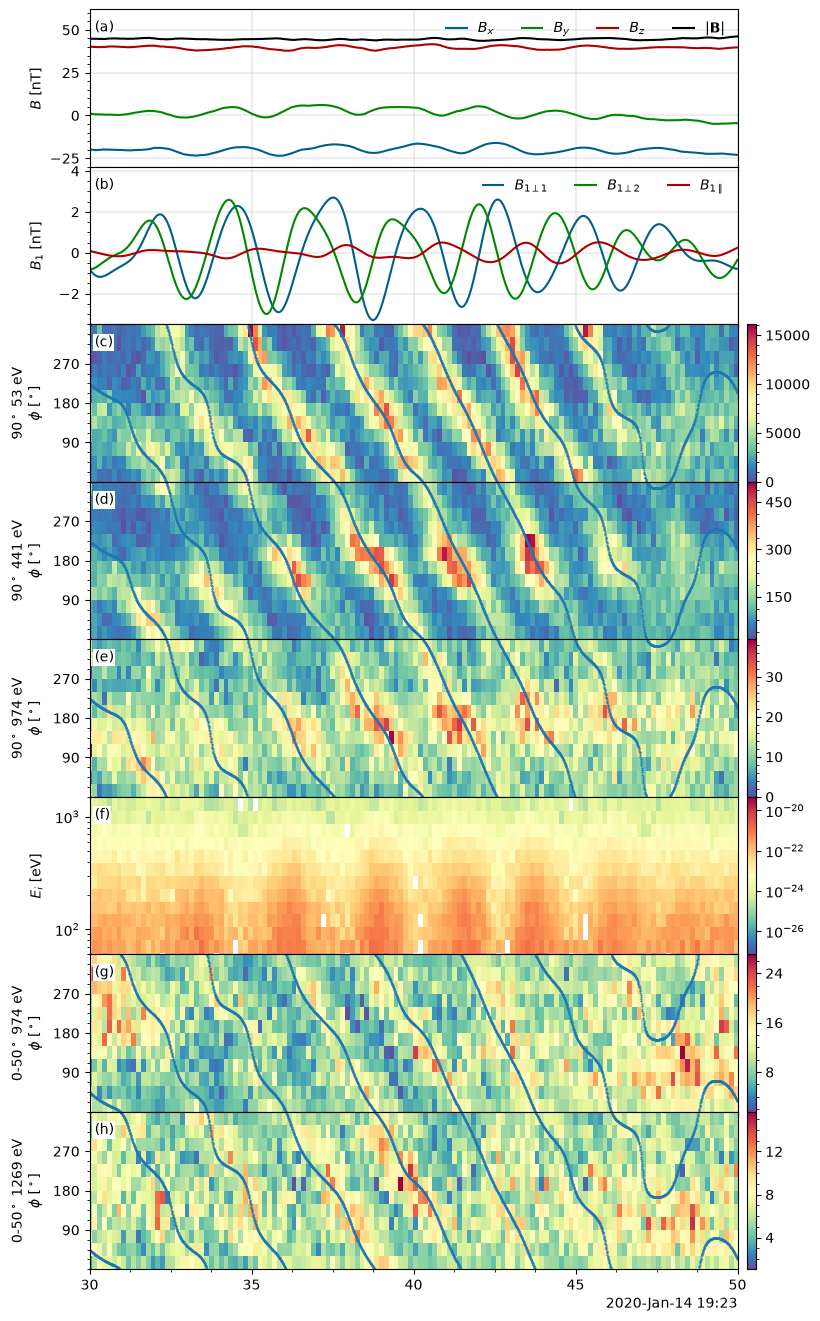

In [7]:
legend_options = dict(ncol=4, handlelength=1.5, loc="upper right", frameon=False)

f, axs = plt.subplots(8, sharex="all", figsize=(9, 14))
f.subplots_adjust(hspace=0, left=0.1, right=0.82, bottom=0.05, top=0.95)

plot_line(axs[0], pyrf.time_clip(b_gse[0], tint))
plot_line(axs[0], pyrf.norm(pyrf.time_clip(b_gse[0], tint)), color="k")
axs[0].set_ylabel("$B$ [nT]")
axs[0].set_ylim([-30, 62])
axs[0].legend(["$B_x$", "$B_y$", "$B_z$", r"$|\mathbf{B}|$"], **legend_options)

plot_line(axs[1], b1_fac)
axs[1].set_ylabel("$B_1$ [nT]")
axs[1].set_ylim([-3.5, 4.2])
axs[1].legend(
    ["$B_{1\\perp 1}$", "$B_{1\\perp 2}$", "$B_{1\\parallel}$"],
    **legend_options,
)

panels = [
    (gpd_perp[53], phi_b1, "90$^\\circ$ 53 eV"),
    (gpd_perp[441], phi_b1, "90$^\\circ$ 441 eV"),
    (gpd_perp[974], phi_b1, "90$^\\circ$ 974 eV"),
]
for ax, (spec, phase, label) in zip(axs[2:5], panels):
    plot_spectr(ax, 1e25 * spec, cmap="Spectral_r")
    ax.plot(phase.time.data, phase.data, ".", color="tab:blue", markersize=1)
    ax.set_ylabel(f"{label}\n" + "$\\phi$ [$^\\circ$]")

plot_spectr(axs[5], spec_e, yscale="log", cscale="log", cmap="Spectral_r")
axs[5].set_ylabel("$E_i$ [eV]")
axs[5].set_ylim([60, 1500])

phase_anti = pyrf.ts_scalar(phi_b1.time.data, (phi_b1.data + 180.0) % 360.0)
for ax, energy in zip(axs[6:], [974, 1269]):
    plot_spectr(ax, 1e25 * gpd_para[energy], cmap="Spectral_r")
    ax.plot(phase_anti.time.data, phase_anti.data, ".", color="tab:blue", markersize=1)
    ax.set_ylabel(f"0-50$^\\circ$ {energy} eV\n" + "$\\phi$ [$^\\circ$]")

for ax in axs[2:5].tolist() + axs[6:].tolist():
    ax.set_ylim([0, 360])
    ax.set_yticks([90, 180, 270])

axs[-1].set_xlim(np.datetime64(tint[0]), np.datetime64(tint[1]))
label_options = dict(bbox=dict(facecolor="white", edgecolor="none", pad=1))
make_labels(axs, [0.008, 0.86], **label_options)
f.align_ylabels(axs)

The perpendicular ions are bunched in gyrophase along $\mathbf{B}_1$ from 53 eV to about 1 keV, the bunches rotating with the wave field in the left-hand sense (decreasing gyrophase), and the quasi-parallel ions at 974 and 1269 eV are enhanced in the $-\mathbf{B}_1$ direction, as in Fig. 1g to 1l of the paper. The colour bars are the phase-space density in units of $10^{-25}$ s$^3$ cm$^{-6}$ (log10 of the phase-space density in s$^3$ cm$^{-6}$ for the energy spectrum).